# 01 · Descriptive EDA (P11)

Descriptive only: no comparison of paid vs unpaid prescribers' prescribing after payment (that waits for the P12 pre-registration). Every figure is built by `ppg.viz.figures`; this notebook runs it and shows the outputs. All cells shown are aggregates with ≥ 11 prescribers.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from ppg import config
from ppg.viz import figures

stats = figures.build()
F, Q = config.FIGURE_DIR, config.QA_DIR

## Chart 3 · Part D spending on GLP-1s by brand

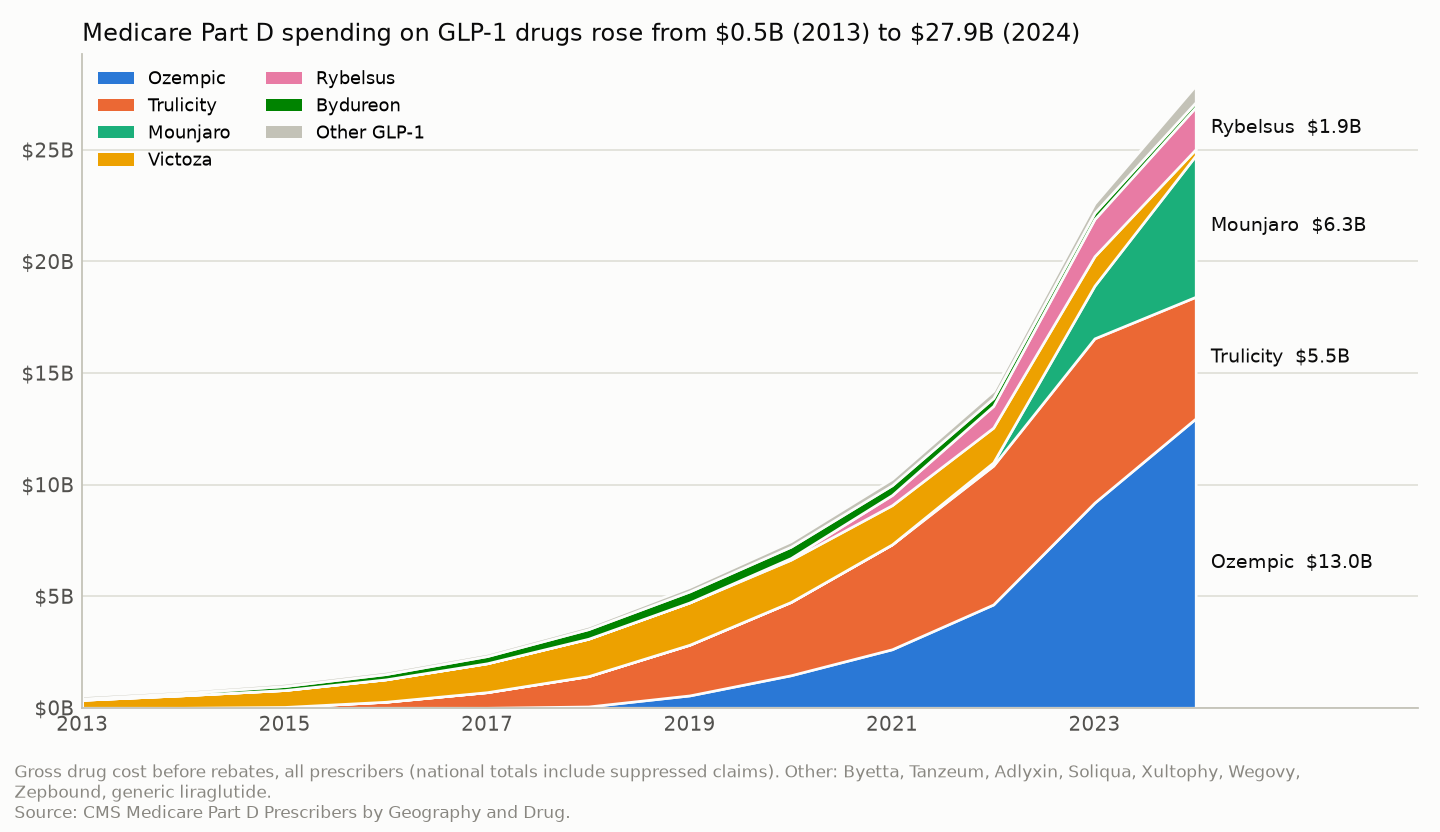

brand,Adlyxin,Bydureon,Byetta,Mounjaro,Ozempic,Rybelsus,Soliqua,Tanzeum,Trulicity,Victoza,Wegovy,Xultophy,Zepbound,liraglutide (generic)
year,,,,,,,,,,,,,,
2013,NaN,0.06,0.14,NaN,NaN,NaN,NaN,NaN,NaN,0.36,NaN,NaN,NaN,NaN
2014,NaN,0.11,0.13,NaN,NaN,NaN,NaN,0.00,0.00,0.56,NaN,NaN,NaN,NaN
2015,NaN,0.18,0.12,NaN,NaN,NaN,NaN,0.02,0.04,0.76,NaN,NaN,NaN,NaN
2016,NaN,0.24,0.11,NaN,NaN,NaN,NaN,0.03,0.27,1.00,NaN,NaN,NaN,NaN
2017,0.0,0.32,0.10,NaN,NaN,NaN,0.01,0.03,0.70,1.30,NaN,0.00,NaN,NaN
2018,0.0,0.43,0.08,NaN,0.06,NaN,0.03,0.01,1.36,1.68,NaN,0.03,NaN,NaN
2019,0.0,0.49,0.06,NaN,0.55,0.00,0.08,0.00,2.27,1.89,NaN,0.06,NaN,NaN
2020,0.0,0.51,0.05,NaN,1.46,0.07,0.12,NaN,3.28,1.90,NaN,0.07,NaN,NaN
2021,0.0,0.44,0.04,NaN,2.62,0.45,0.17,NaN,4.70,1.76,NaN,0.08,NaN,NaN


In [2]:
display(Image(F / 'chart3_partd_glp1_spending.png'))
sp = pd.read_csv(Q / 'eda_partd_glp1_spending.csv')
(sp.pivot_table(index='year', columns='brand', values='cost', aggfunc='sum') / 1e9).round(2)

## Chart 4 · Payments naming each brand, by payment type

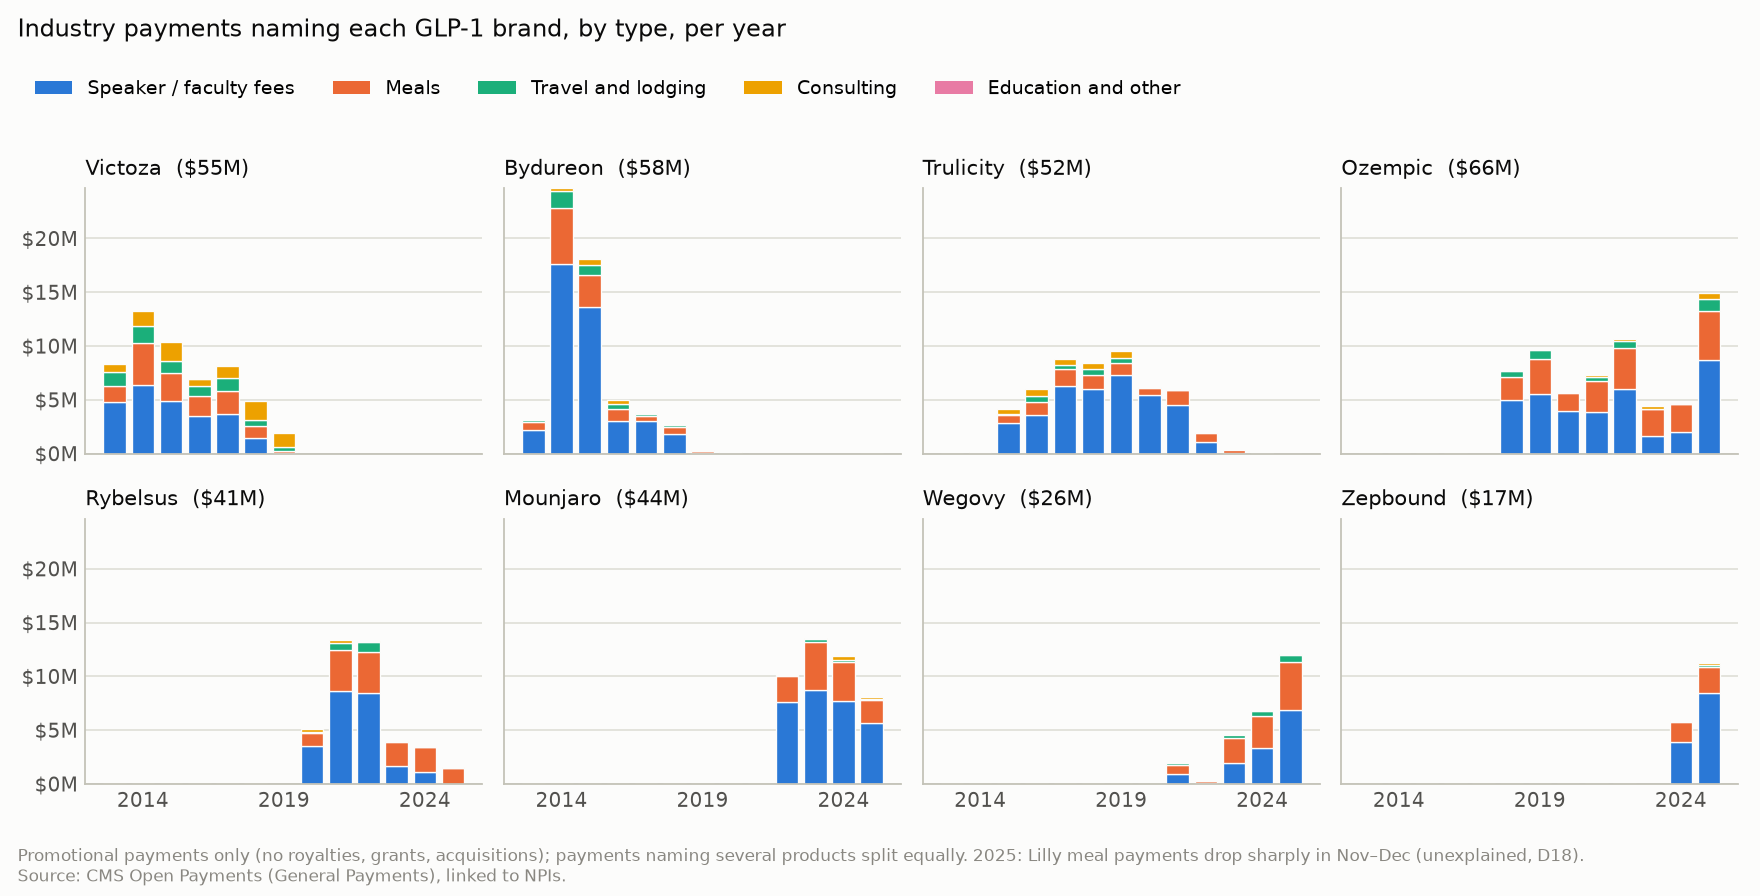

{'glp1_promo_usd_by_type_share': {'usd_speaker': 0.5934,
  'usd_food_beverage': 0.2789,
  'usd_travel': 0.0659,
  'usd_consulting': 0.0617,
  'usd_other': 0.0002}}

In [3]:
display(Image(F / 'chart4_payments_by_brand_type.png'))
stats['chart4']

## Chart 6 · Payments per Part D enrollee with diabetes, by state (2024)

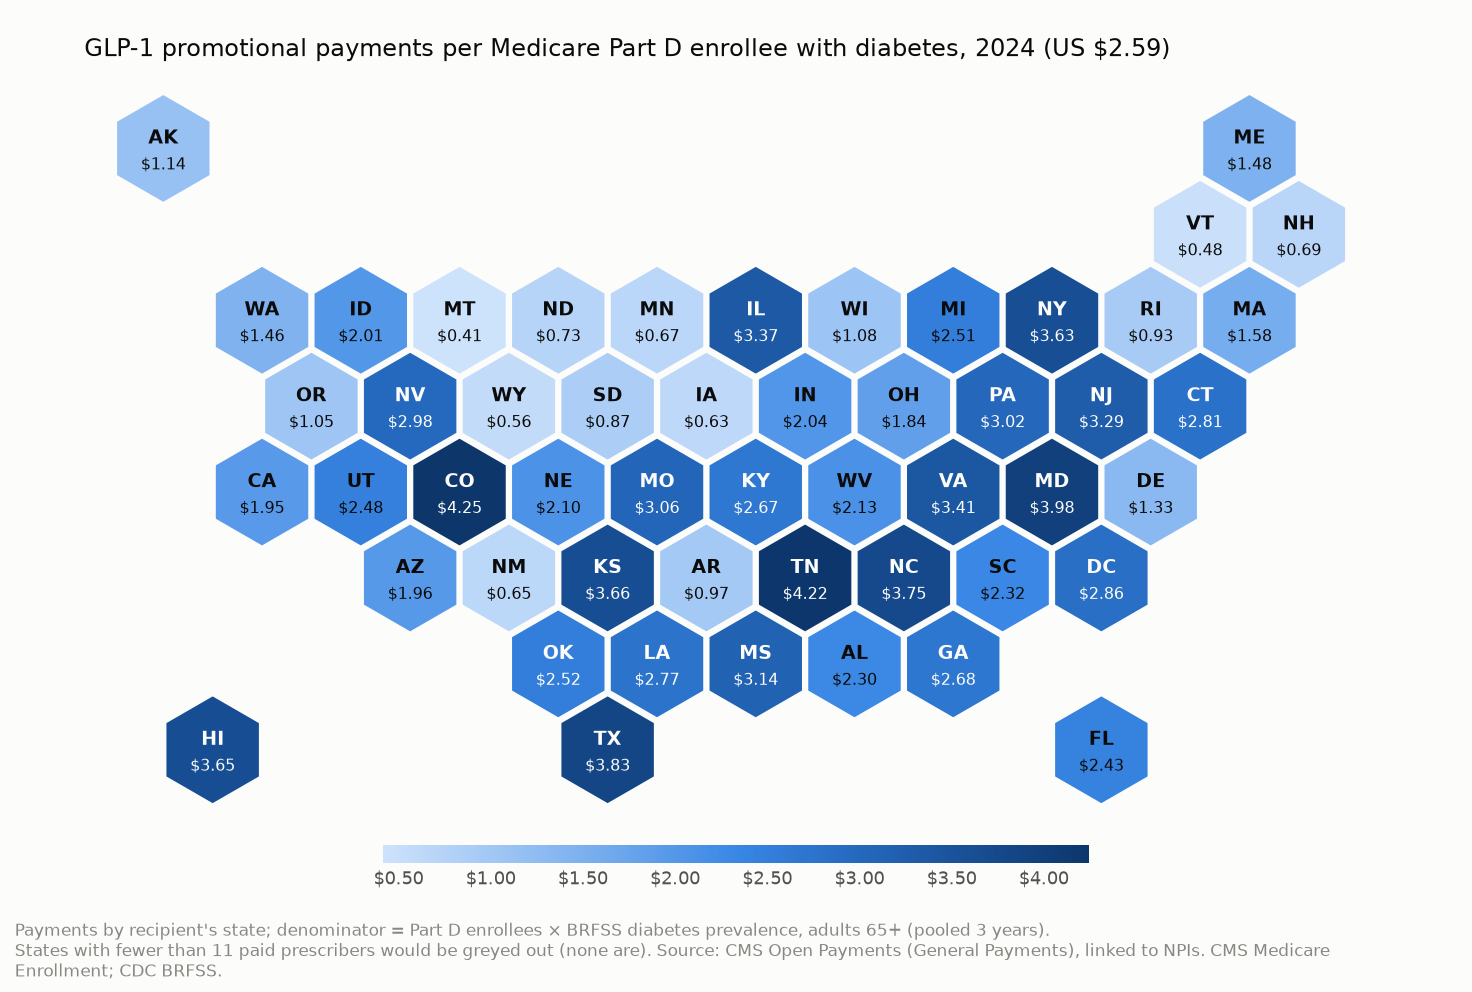

,state,usd,npis_paid,est_diabetic_partd,usd_per_diabetic
0,CO,6.241003e+05,1467,1.469774e+05,4.2462
1,TN,1.378833e+06,4409,3.266730e+05,4.2208
2,MD,7.687926e+05,2545,1.930986e+05,3.9813
3,TX,4.048331e+06,11817,1.055851e+06,3.8342
4,NC,1.637067e+06,5795,4.364560e+05,3.7508
5,KS,3.955994e+05,1769,1.080640e+05,3.6608
6,HI,1.683583e+05,405,4.614296e+04,3.6486
7,NY,2.658996e+06,7682,7.320386e+05,3.6323
8,VA,1.079685e+06,3561,3.161664e+05,3.4149
9,IL,1.542361e+06,4129,4.573902e+05,3.3721


In [4]:
display(Image(F / 'chart6_state_payments_per_diabetic.png'))
pd.read_csv(Q / 'eda_state_payments_per_diabetic.csv')[['state', 'usd', 'npis_paid', 'est_diabetic_partd', 'usd_per_diabetic']].head(10)

## Chart 7 · Concentration of payment dollars

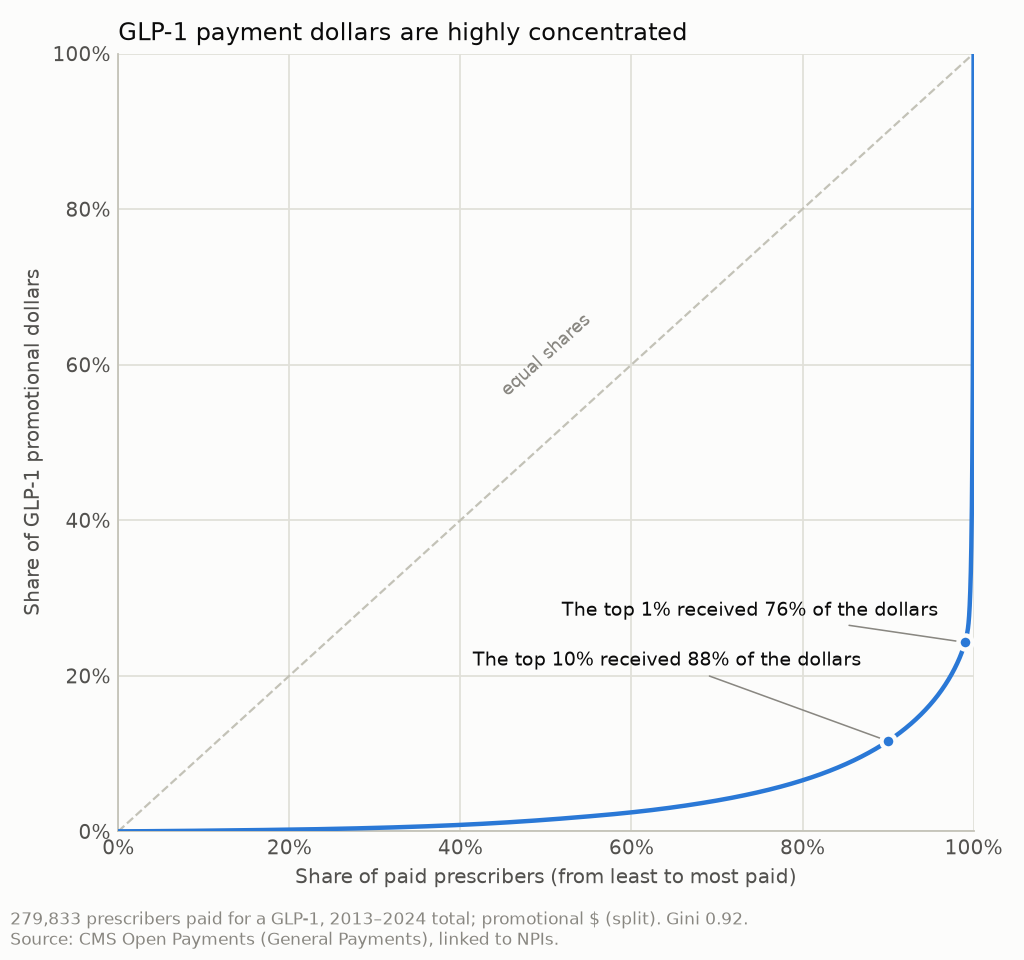

,2013-2024,2024
npis,279833.000000,125328.000000
top1_share,0.757058,0.620545
top10_share,0.883971,0.745869
bottom50_share,0.014856,0.052463
gini,0.921064,0.811934
median_usd,108.620000,61.050000
p99_usd,5239.777787,642.967300


In [5]:
display(Image(F / 'chart7_lorenz_payments.png'))
pd.DataFrame({'2013-2024': stats['chart7'], '2024': stats['concentration_2024']})

## Secondary question 3 · Payments relative to diabetes workload, by specialty (2024)

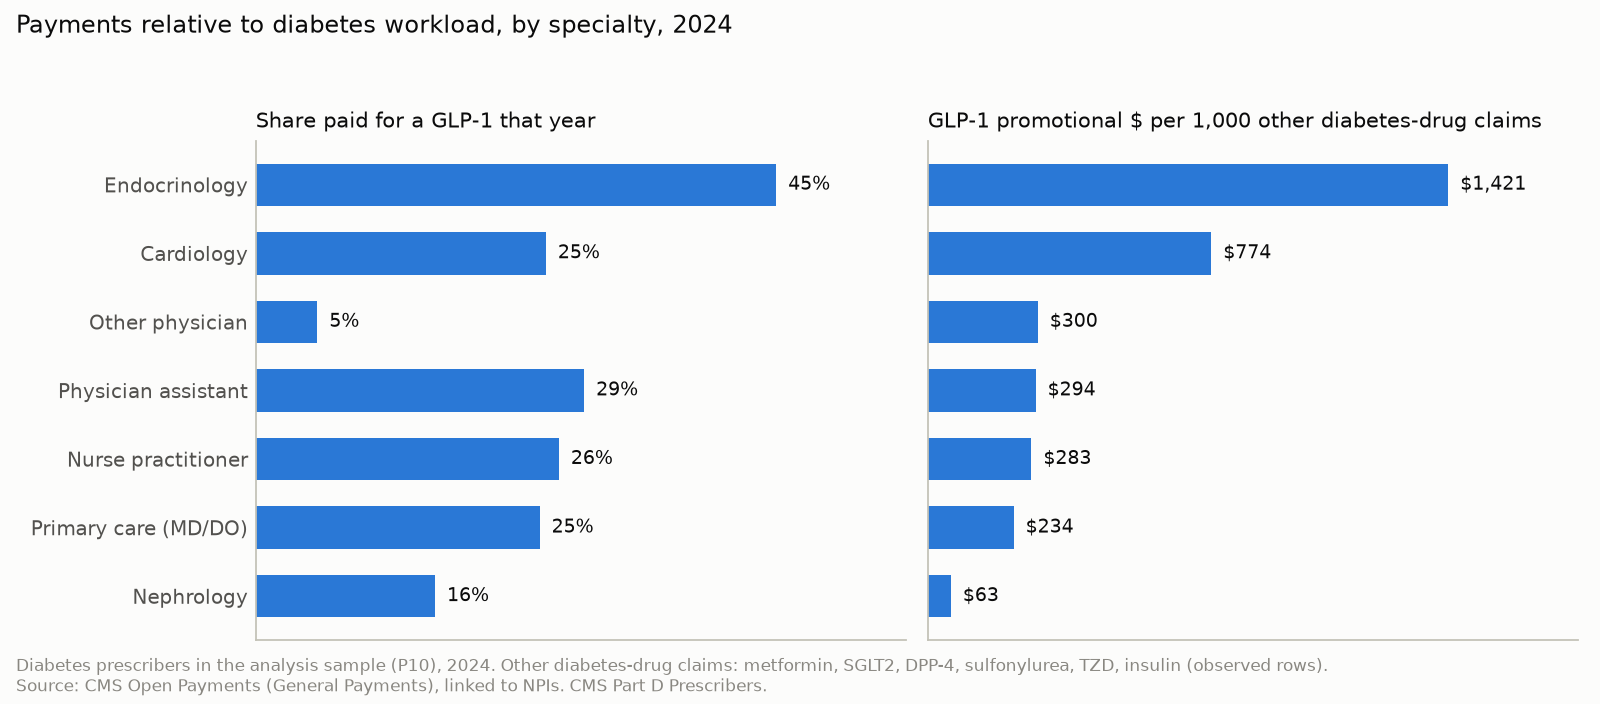

,specialty_group,prescribers,share_paid,usd_per_1000_dm_claims,usd_per_prescriber
0,nephrology,6872,0.1564,62.7096,8.5156
1,other_nonphysician,214,0.0981,132.1621,11.4641
2,primary_care_physician,179168,0.2477,234.1154,68.4154
3,nurse_practitioner,92825,0.2645,282.6901,41.4767
4,physician_assistant,31577,0.2865,294.1798,41.3358
5,other_physician,25855,0.0537,300.0916,14.5649
6,cardiology,15942,0.2532,773.8803,87.2714
7,endocrinology,5864,0.4541,1421.0293,1612.3017


In [6]:
display(Image(F / 'chart_specialty_payments_vs_load.png'))
pd.read_csv(Q / 'eda_specialty_payments_vs_load.csv')[['specialty_group', 'prescribers', 'share_paid', 'usd_per_1000_dm_claims', 'usd_per_prescriber']]